## 01. Data Exploration and Wrangling

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import unicodedata
import string
import re
import spacy

from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parents[0]))

from src import preprocessing

df = pd.read_csv('../data/raw/ph_sms_dataset.csv')
df.sample(10)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LEI\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,masked_celphone_number,hashed_cellphone_number,date,text,carrier,Target
303,+63985****958,75159592-7275-3651-8fa2-0a4e0aeeedfa,2024-04-06 08:42:37.673,T.G.I.S. on WinningPlus! Claim your Special bo...,Smart/TNT,Spam
973,+63981****852,f66589b7-4e6a-33ba-b7c5-d0dacb48552b,2022-11-12 14:33:48.916,"My god, at least 999P rewards waiting for you\...",Smart,Legitimate (ham)
1005,+63918****279,29df0ed1-5898-35b4-b891-144c59633b19,2018-09-25 08:36:14.944,The Biggest redevelopment along C5 in now ongo...,Smart,Spam
339,+63964****098,6cd7a455-12c0-3ad3-80c1-7472b5bb62c5,2024-04-01 10:16:13.839,"Magparehistro para sa libreng ₱7777, tumaya: l...",Globe,Legitimate (ham)
746,+63938****570,eb4588e9-7e65-348a-8739-9b7b3306223e,2023-08-28 12:40:09.955,BDO-WARNING:\n\nA suspicious login was detecte...,TNT,Smishing (scam)
932,+63970****285,9ea603bd-39a8-33d0-a357-f1e761c0bb3b,2022-12-05 14:10:00.186,M0nday na! Bigyan natin ng suwerte ang araw mo...,Smart,Smishing (scam)
259,+63985****426,dee07c28-ddd2-3137-a801-e6da4db41484,2024-04-20 06:08:53.937,I-double mo na ang saya at panalo mo.100% dep...,Smart/TNT,Smishing (scam)
398,+63985****800,d4fbfb04-b0ab-31e0-9758-3b016ccc81f2,2024-03-20 05:25:18.084,luckph.tv/2OrhrRrO Maglaro at manalo nang wala...,Smart/TNT,Smishing (scam)
340,+63930****452,fca5b555-21df-37ed-8a19-6da39c499b96,2024-04-01 06:17:10.621,"Good day from GCash,\n\nPlease be advised that...",TNT,Smishing (scam)
287,+63985****415,97fda49a-fd39-3ce6-9f81-b0df6b444080,2024-04-09 12:21:59.956,"2.Mag-recharge get 100% bonus, gamitin ang 100...",Smart/TNT,Smishing (scam)


In [2]:
df.isna().sum()

masked_celphone_number     0
hashed_cellphone_number    0
date                       0
text                       0
carrier                    0
Target                     0
dtype: int64

In [3]:
df.duplicated().sum()

np.int64(0)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1021 entries, 0 to 1020
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   masked_celphone_number   1021 non-null   str  
 1   hashed_cellphone_number  1021 non-null   str  
 2   date                     1021 non-null   str  
 3   text                     1021 non-null   str  
 4   carrier                  1021 non-null   str  
 5   Target                   1021 non-null   str  
dtypes: str(6)
memory usage: 48.0 KB


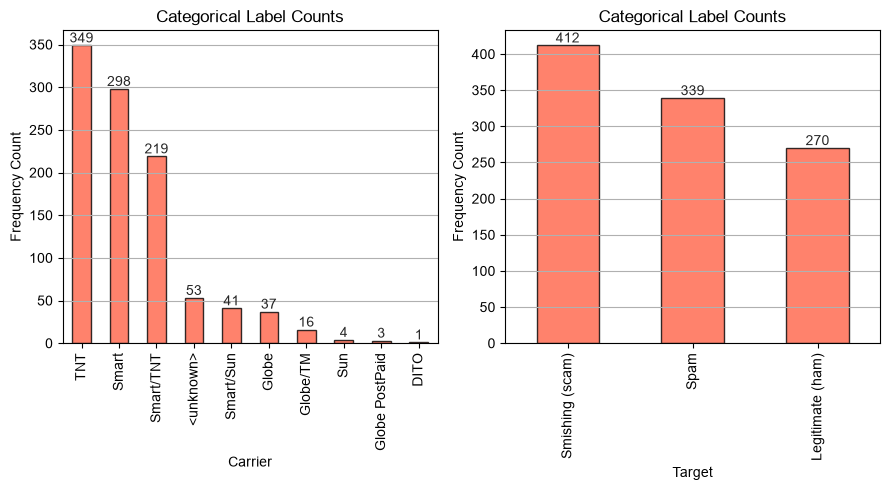

In [5]:
categoricals = ['carrier', 'Target']

fig, ax = plt.subplots(1, 2, figsize=(9, 5))

sns.set_style('whitegrid')
for i, cats in enumerate(categoricals):
    counts = df[cats].value_counts().sort_values(ascending=False)
    counts.plot(kind='bar', alpha=0.8, ax=ax[i], edgecolor='black', color='tomato')
    ax[i].set_ylabel('Frequency Count')
    ax[i].set_xlabel(f"{cats.title()}")
    ax[i].set_title('Categorical Label Counts')
    ax[i].bar_label(ax[i].containers[0])
    ax[i].grid(axis='x')
plt.tight_layout()


## Data Cleaning

In [8]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

clean = preprocessing.transform(df, encoder=encoder, is_train=True)

clean


# save data
clean.to_csv('../data/processed/sms_cleaned_data.csv', index=False)